# Yellow cards and shots on target

Yellow card columns in `combined_data.csv`:

* **HY**: home yellow cards
* **AY**: away yellow cards

Other columns used: `FTR` (full-time result), `HST` and `AST` (shots on target), `HTHG` and `HTAG` (half-time goals). The same two checks as in `red_and_shots.ipynb` are run here, for yellow cards.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("combined_data.csv")

## Yellows by referee and club

Each row is one referee and one club they officiated, home and away together. **Yellows per match** is how many yellow cards that club got per match under that referee. **Club usual** is that club's yellows per match with every referee. **Above club usual** is the difference, so a positive number means the club gets more yellows than usual under that referee.

Yellows are common, so a referee and club pair needs at least `MIN_MATCHES` matches (15 by default, set at the top of the cell) to be shown. This is the yellow-card version of the referee and club table in `red_and_shots.ipynb`.

In [ ]:
# Yellows by referee and club (home and away together)
# One row per referee and club pair. Pairs with only a few matches are left out.
MIN_MATCHES = 15

home = df[["Referee", "HomeTeam", "HY"]].rename(columns={"HomeTeam": "Team", "HY": "yellows"})
away = df[["Referee", "AwayTeam", "AY"]].rename(columns={"AwayTeam": "Team", "AY": "yellows"})
long = pd.concat([home, away], ignore_index=True)

team_rate = long.groupby("Team")["yellows"].mean()
ref_rate = long.groupby("Referee")["yellows"].mean()
pair = long.groupby(["Referee", "Team"]).agg(matches=("yellows", "size"), yellows=("yellows", "sum"))
pair["yellows per match"] = pair["yellows"] / pair["matches"]
pair["club usual"] = pair.index.get_level_values("Team").map(team_rate)
pair["referee usual"] = pair.index.get_level_values("Referee").map(ref_rate)
pair["above club usual"] = pair["yellows per match"] - pair["club usual"]
pair = pair[pair["matches"] >= MIN_MATCHES]

print("Yellows per match in total:", round(long["yellows"].mean(), 2))
print(f"{len(pair)} referee and club pairs with at least {MIN_MATCHES} matches\n")
print("Pairs that give the club the most yellows compared with the club's usual")
display(pair.sort_values("above club usual", ascending=False).head(15).round(2))
print("\nPairs that give the club the fewest yellows compared with the club's usual")
display(pair.sort_values("above club usual").head(10).round(2))

# Chart: top 10 and bottom 10 pairs
top = pd.concat([pair.sort_values("above club usual").head(10), pair.sort_values("above club usual").tail(10)])
labels = [f"{r} - {t}" for r, t in top.index]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(labels, top["above club usual"], color=["tab:green" if v < 0 else "tab:red" for v in top["above club usual"]])
ax.axvline(0, color="gray", lw=1)
ax.set_xlabel("Yellows per match above (+) or below (-) the club's usual")
ax.set_title("Referee and club pairs with the biggest gap in yellows")
fig.tight_layout()
plt.show()

The pair that stands out most is **C Pawson** and **Wolves**: 2.88 yellows per match in 16 matches, against a Wolves usual of 1.89. Next are J Gillett and Tottenham (2.73 against 2.02), S Hooper and Newcastle, and D England and Crystal Palace. At the other end, A Taylor gives Wolves only 1.40 per match, and C Kavanagh gives Tottenham 1.59 against a usual of 2.02.

These pairs rest on 15 to 28 matches, and 74 pairs are checked, so a few large gaps are expected by chance alone. Treat the top rows as pairs to look at more closely, not as proof that a referee targets a club.

## What "many yellows" means

A yellow is far more common than a red, so **many yellows** means `YELLOW_LIMIT` or more yellow cards for one side in one match (3 by default, set at the top of each code cell). A club with 0 to 2 yellows is at its usual. A match where both teams had many yellows is left out.

1. **Points:** each club's points per match with many yellows against its usual, shown in two tables (clubs that lose points and clubs that earn points), with the % change vs usual and the shots on target.
2. **Chance of winning:** win, draw and loss % by situation, the half-time split, a club view, and a simple model.

A yellow is not a sending-off, and a team that is behind often picks up more yellows while chasing the game. So these results show what goes with many yellows, not what the yellows cause.

17 clubs lose points when they have many yellows, 11 earn points.
A % change of -50 means the club takes about half its usual points; +50 means half as many again.

Clubs that LOSE points when they have many yellows


,many-yellow matches,"points, usual","points, many yellows",points change,% change vs usual,"shots on target, usual","shots on target, many yellows",shots on target change,"points per shot on target, usual","points per shot on target, many yellows"
Team,,,,,,,,,,
Newcastle,34,1.49,0.76,-0.72,-48.64,4.44,3.18,-1.26,0.34,0.24
Man City,32,2.47,1.75,-0.72,-29.07,6.39,5.69,-0.71,0.39,0.31
Arsenal,27,2.16,1.52,-0.64,-29.63,5.16,3.67,-1.49,0.42,0.41
Man United,65,1.74,1.34,-0.40,-22.94,5.52,4.55,-0.96,0.31,0.29
Liverpool,28,2.15,1.79,-0.37,-17.13,5.93,5.21,-0.71,0.36,0.34
Brighton,32,1.46,1.09,-0.36,-25.00,4.72,4.06,-0.65,0.31,0.27
Leicester,26,1.31,0.96,-0.34,-26.40,4.28,4.00,-0.28,0.31,0.24
West Ham,36,1.28,0.94,-0.33,-25.94,4.04,3.69,-0.34,0.32,0.26
Wolves,46,1.17,0.87,-0.30,-25.85,3.72,3.39,-0.33,0.32,0.26



Clubs that EARN points when they have many yellows


,many-yellow matches,"points, usual","points, many yellows",points change,% change vs usual,"shots on target, usual","shots on target, many yellows",shots on target change,"points per shot on target, usual","points per shot on target, many yellows"
Team,,,,,,,,,,
Norwich,15,0.38,1.07,0.69,184.44,2.90,3.00,0.10,0.13,0.36
Watford,13,0.56,1.15,0.60,106.73,3.14,2.92,-0.22,0.18,0.39
Sunderland,10,0.94,1.50,0.56,59.38,3.06,3.30,0.24,0.31,0.45
Ipswich,8,0.40,0.88,0.48,118.75,3.00,2.75,-0.25,0.13,0.32
Sheffield United,30,0.73,0.97,0.24,32.92,3.09,3.20,0.11,0.24,0.30
Crystal Palace,60,1.03,1.25,0.22,21.48,3.80,3.87,0.07,0.27,0.32
Bournemouth,49,1.12,1.33,0.21,18.62,4.11,4.33,0.22,0.27,0.31
Brentford,34,1.32,1.53,0.21,15.49,4.33,4.35,0.02,0.31,0.35
Aston Villa,42,1.26,1.40,0.14,11.47,4.52,4.45,-0.07,0.28,0.32



Correlation of the points change with the shots-on-target change: 0.70


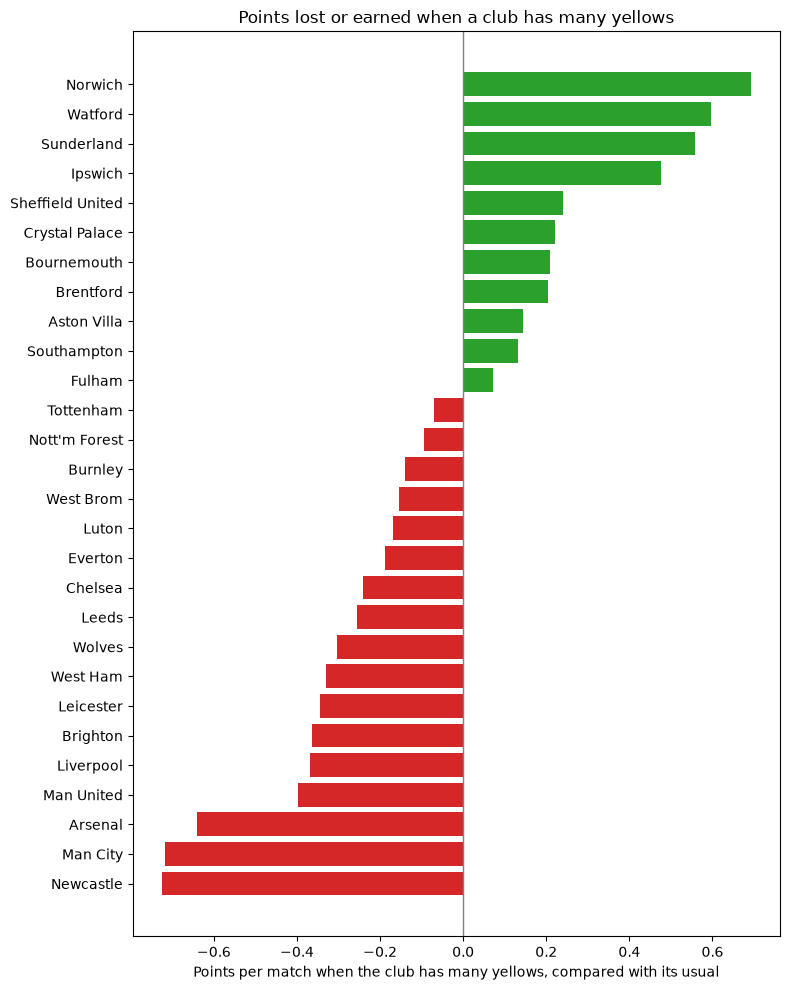

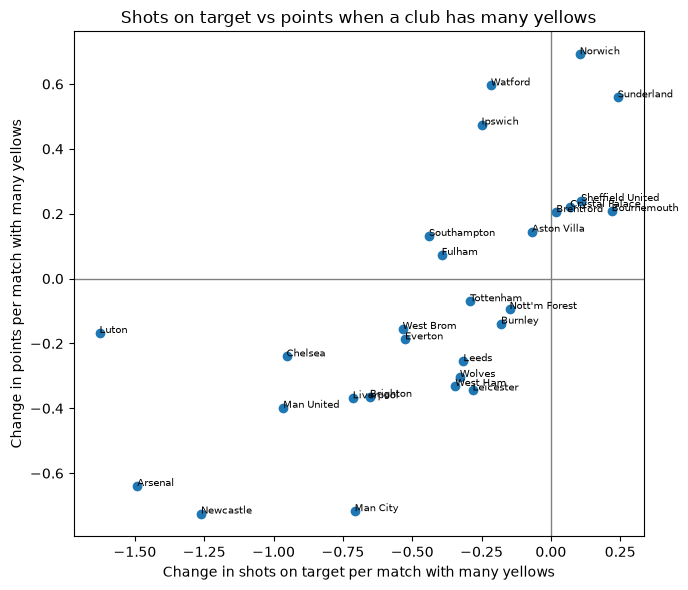

In [2]:
# When a club picks up many yellow cards: does it earn or lose points, by how much, and what happens to its shots on target?
# Yellow cards come from HY (home) and AY (away). "Many yellows" means YELLOW_LIMIT or more in one match.
# A match where both teams had many yellows is left out. Change YELLOW_LIMIT to test another cut-off.
YELLOW_LIMIT = 3
home = pd.DataFrame({
    "Team": df["HomeTeam"], "own": df["HY"] >= YELLOW_LIMIT, "opp": df["AY"] >= YELLOW_LIMIT,
    "pts": df["FTR"].map({"H": 3, "D": 1, "A": 0}), "sot": df["HST"],
})
away = pd.DataFrame({
    "Team": df["AwayTeam"], "own": df["AY"] >= YELLOW_LIMIT, "opp": df["HY"] >= YELLOW_LIMIT,
    "pts": df["FTR"].map({"A": 3, "D": 1, "H": 0}), "sot": df["AST"],
})
x = pd.concat([home, away], ignore_index=True)
x = x[~(x["own"] & x["opp"])]

have = x[x["own"]]                    # the club has many yellows
usual = x[~x["own"] & ~x["opp"]]      # few yellows on both sides = the club's usual

def per_team(d):
    g = d.groupby("Team")
    return pd.DataFrame({
        "matches": g.size(),
        "points": g["pts"].mean(),
        "sot": g["sot"].mean(),
        "points per sot": g["pts"].sum() / g["sot"].sum(),
    })

h, u = per_team(have), per_team(usual)
t = pd.DataFrame({
    "many-yellow matches": h["matches"],
    "points, usual": u["points"],
    "points, many yellows": h["points"],
    "points change": h["points"] - u["points"],
    "% change vs usual": (h["points"] - u["points"]) / u["points"] * 100,
    "shots on target, usual": u["sot"],
    "shots on target, many yellows": h["sot"],
    "shots on target change": h["sot"] - u["sot"],
    "points per shot on target, usual": u["points per sot"],
    "points per shot on target, many yellows": h["points per sot"],
}).dropna()

lose = t[t["points change"] < 0].sort_values("points change")
earn = t[t["points change"] > 0].sort_values("points change", ascending=False)

print(f"{len(lose)} clubs lose points when they have many yellows, {len(earn)} earn points.")
print("A % change of -50 means the club takes about half its usual points; +50 means half as many again.\n")
print("Clubs that LOSE points when they have many yellows")
display(lose.round(2))
print("\nClubs that EARN points when they have many yellows")
display(earn.round(2))

# Does the points change follow the change in shots on target?
r_sot = t["points change"].corr(t["shots on target change"])
print(f"\nCorrelation of the points change with the shots-on-target change: {r_sot:.2f}")

# Chart: points change by club, loss in red and earn in green
p = t.sort_values("points change")
fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(p.index, p["points change"], color=["tab:red" if v < 0 else "tab:green" for v in p["points change"]])
ax.axvline(0, color="gray", lw=1)
ax.set_xlabel("Points per match when the club has many yellows, compared with its usual")
ax.set_title("Points lost or earned when a club has many yellows")
fig.tight_layout()
plt.show()

# Chart: shots on target change vs points change
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(t["shots on target change"], t["points change"])
for name, row in t.iterrows():
    ax.annotate(name, (row["shots on target change"], row["points change"]), fontsize=7)
ax.axhline(0, color="gray", lw=1)
ax.axvline(0, color="gray", lw=1)
ax.set_xlabel("Change in shots on target per match with many yellows")
ax.set_ylabel("Change in points per match with many yellows")
ax.set_title("Shots on target vs points when a club has many yellows")
fig.tight_layout()
plt.show()

In [3]:
# How a club's chance of winning changes when it picks up many yellow cards
# Yellow cards come from HY (home) and AY (away). "Many yellows" means YELLOW_LIMIT or more in one match.
# Half-time goals (HTHG, HTAG) show how the match stood before the second half.
YELLOW_LIMIT = 3
import numpy as np

home = pd.DataFrame({
    "Team": df["HomeTeam"], "home": 1, "own": df["HY"] >= YELLOW_LIMIT, "opp": df["AY"] >= YELLOW_LIMIT,
    "res": df["FTR"].map({"H": "Win", "D": "Draw", "A": "Loss"}),
    "ht": df["HTHG"] - df["HTAG"],
})
away = pd.DataFrame({
    "Team": df["AwayTeam"], "home": 0, "own": df["AY"] >= YELLOW_LIMIT, "opp": df["HY"] >= YELLOW_LIMIT,
    "res": df["FTR"].map({"A": "Win", "D": "Draw", "H": "Loss"}),
    "ht": df["HTAG"] - df["HTHG"],
})
w = pd.concat([home, away], ignore_index=True)
w["win"] = (w["res"] == "Win").astype(int)

clean = w[~(w["own"] & w["opp"])].copy()       # many yellows on both sides is left out here
clean["case"] = "few yellows"
clean.loc[clean["own"], "case"] = "have many yellows"
clean.loc[clean["opp"], "case"] = "opponent has many yellows"
order = ["few yellows", "have many yellows", "opponent has many yellows"]

# 1. League: win / draw / loss % by situation, home and away
res = clean.groupby(["home", "case"])["res"].value_counts(normalize=True).unstack().fillna(0) * 100
res["matches"] = clean.groupby(["home", "case"]).size()
res.index = res.index.set_levels(["Away", "Home"], level=0).set_names(["Venue", "Situation"])
print("League: win, draw and loss % by situation")
display(res[["Win", "Draw", "Loss", "matches"]].reindex(order, level=1).round(1))

# 2. Same, split by the half-time score from the club's side
clean["half-time"] = pd.cut(clean["ht"], [-99, -1, 0, 99], labels=["behind", "level", "ahead"])
ht = clean.pivot_table(index="half-time", columns="case", values="win", aggfunc="mean", observed=True)[order] * 100
htn = clean.pivot_table(index="half-time", columns="case", values="win", aggfunc="size", observed=True)[order]
print("\nWin % by half-time score and situation")
display(ht.round(1))
print("Matches behind each figure")
display(htn)

# 3. Club view: win % with many yellows vs few
g = clean[clean["case"].isin(["few yellows", "have many yellows"])]
c = g.pivot_table(index="Team", columns="case", values="win", aggfunc="mean") * 100
c["many-yellow matches"] = g[g["case"] == "have many yellows"].groupby("Team").size()
club = pd.DataFrame({
    "many-yellow matches": c["many-yellow matches"],
    "win %, few yellows": c["few yellows"],
    "win %, many yellows": c["have many yellows"],
    "change (percentage points)": c["have many yellows"] - c["few yellows"],
}).dropna().sort_values("change (percentage points)")
print("\nClub view: win % with many yellows and with few")
display(club.round(1))

# 4. A simple model: chance of a win from home, yellows, half-time score and the club's usual strength
w["strength"] = w["Team"].map(w[~w["own"] & ~w["opp"]].groupby("Team")["win"].mean())
X = pd.DataFrame({
    "home": w["home"], "have many yellows": w["own"].astype(int),
    "opponent has many yellows": w["opp"].astype(int), "half-time goal margin": w["ht"],
    "club's usual win rate": w["strength"],
})
# Logistic regression fitted with plain NumPy (Newton's method), so no extra package is needed
def fit_logit(X, y, steps=50):
    A = np.column_stack([np.ones(len(X)), X.to_numpy(float)])
    beta = np.zeros(A.shape[1])
    for _ in range(steps):
        p = 1 / (1 + np.exp(-A @ beta))
        grad = A.T @ (y - p)
        hess = A.T @ (A * (p * (1 - p))[:, None]) + 1e-8 * np.eye(A.shape[1])
        step = np.linalg.solve(hess, grad)
        beta += step
        if np.abs(step).max() < 1e-8:
            break
    return beta

beta = fit_logit(X, w["win"].to_numpy(float))
odds = pd.Series(np.exp(beta[1:]), index=X.columns, name="odds multiplier")
print("\nModel: each factor multiplies the odds of winning by this amount (below 1 lowers them)")
display(odds.round(2).to_frame())

def win_chance(row):
    return 1 / (1 + np.exp(-(beta[0] + np.dot(beta[1:], row))))

# Scenarios for a club with an average usual win rate, level at half-time
avg = w["strength"].mean()
rows = []
for venue, h_ in [("Home", 1), ("Away", 0)]:
    for name, own, opp in [("few yellows", 0, 0), ("have many yellows", 1, 0), ("opponent has many yellows", 0, 1)]:
        p = win_chance([h_, own, opp, 0, avg])
        rows.append({"Venue": venue, "Situation": name, "chance of winning %": p * 100})
print("\nChance of winning for an average club, level at half-time")
display(pd.DataFrame(rows).pivot(index="Situation", columns="Venue", values="chance of winning %").reindex(order).round(1))

League: win, draw and loss % by situation


res                               Win  Draw  Loss  matches
Venue Situation                                           
Away  few yellows                33.7  22.1  44.3     1462
      have many yellows          29.6  23.5  46.9      565
      opponent has many yellows  37.3  27.2  35.5      375
Home  few yellows                44.3  22.1  33.7     1462
      have many yellows          35.5  27.2  37.3      375
      opponent has many yellows  46.9  23.5  29.6      565


Win % by half-time score and situation


case,few yellows,have many yellows,opponent has many yellows
half-time,,,
behind,8.9,8.1,12.4
level,31.9,30.7,35.6
ahead,77.5,64.1,75.7


Matches behind each figure


...

,many-yellow matches,"win %, few yellows","win %, many yellows",change (percentage points)
Team,,,,
Arsenal,27,66.4,40.7,-25.7
Newcastle,34,42.3,17.6,-24.7
Man City,32,78.3,56.2,-22.0
Liverpool,28,65.5,50.0,-15.5
Man United,65,49.6,35.4,-14.2
Leicester,26,37.1,23.1,-14.0
West Brom,4,13.8,0.0,-13.8
Leeds,39,31.6,17.9,-13.7
Brighton,32,38.2,25.0,-13.2



Model: each factor multiplies the odds of winning by this amount (below 1 lowers them)


,odds multiplier
home,1.34
have many yellows,0.89
opponent has many yellows,1.01
half-time goal margin,3.78
club's usual win rate,13.59



Chance of winning for an average club, level at half-time


Venue,Away,Home
Situation,,
few yellows,30.6,37.1
have many yellows,28.1,34.4
opponent has many yellows,30.8,37.3


### What this shows

* **Many yellows go with fewer points, but much less than a red.** A home side wins 44.3% of matches with few yellows and 35.5% with many. An away side goes from 33.7% to 29.6%. For comparison, a red takes a home side from 43.7% to 21.5%.
* **The opponent's yellows barely help.** A home side wins 46.9% when the opponent has many yellows, against 44.3% with few.
* **Clubs differ more than with reds.** 17 clubs lose points with many yellows (Newcastle, Man City and Arsenal most) and 11 earn more. The match counts are larger than for reds (often 25 to 65), so the figures are steadier.
* **Shots on target follow the points change closely** (correlation about 0.70, against 0.16 for reds). Clubs whose shots on target hold up with many yellows tend to keep their points.
* **The model:** many yellows multiply the odds of winning by about 0.89 and the opponent's yellows by about 1.01, against about 0.33 and 2.5 for reds. For an average club level at half-time at home, the chance of winning is about 37% with few yellows and 34% with many.
* **Limits:** yellows are a sign of how the match is going as well as a cause, and the 3-yellow cut-off is a choice. Try other values of `YELLOW_LIMIT` to see if the story holds.

### Why a binary logistic regression

The tables above compare averages. They show that a club wins less often when it has many yellow cards, but they cannot separate many yellow cards from the other things that change at the same time. The regression is used to answer one question: **how much does many yellow cards change the chance of winning once home advantage, the half-time score and the club's own strength are held fixed?**

**Why this model fits**

1. **The outcome is yes or no.** A club either wins (1) or does not win (0). Logistic regression is built for a yes or no outcome, and its answer is always a chance between 0% and 100%. An ordinary straight-line regression can predict a chance below 0% or above 100%.
2. **Several things happen at once.** Many yellows are not random either: a team that is behind often picks up more yellows while chasing the game, strong clubs win more often anyway, home sides win more often, and the half-time score already tells a lot about the result. A plain average mixes all of these together. A regression gives each factor its own effect with the others held fixed.
3. **The result is easy to read.** Each factor becomes an odds multiplier (below 1 lowers the chance of winning, above 1 raises it), and the model gives a chance of winning for any situation, such as an average club at home, level at half-time.
4. **It suits the amount of data.** There are 5,320 club-match rows (each match counted once for each side) and only five factors, so the model is not asking more than the data can give.

**Why not something else**

* **Not a regression on points.** Points can only be 0, 1 or 3, which a straight-line regression handles badly. The question here is about winning, so a win or not-win outcome is the direct way to ask it.
* **Not win, draw and loss as three outcomes.** That would be more complete, but it needs a bigger model and is harder to read. Win or not-win keeps it simple and matches the question "is the club more likely to win".

**What it does not do.** It does not prove that many yellow cards causes the change, and it does not know when in the match many yellow cards came. It describes this data, so read it as a guide and not a forecast.

### How the model works (binary logistic regression)

The model in the last code cell is a **binary logistic regression**. The outcome is win (1) or not win (0), and it uses five factors at once. It is fitted with NumPy, using Newton's method (maximum likelihood), so no extra package is needed.

**1. A score z for each club in each match**

```
z = b0 + b1·home + b2·manyYellows + b3·oppManyYellows + b4·halfTimeMargin + b5·usualWinRate
```

**2. From z to a chance of winning**

```
p = 1 / (1 + e^(−z))          odds = p / (1 − p)
```

**3. Each factor multiplies the odds by e^b.** That is the "odds multiplier" table.

| Factor | b | Multiplier (e^b) |
|---|---|---|
| home | 0.293 | 1.34 |
| have many yellows | -0.118 | 0.89 |
| opponent has many yellows | 0.008 | 1.01 |
| half-time goal margin (per goal) | 1.329 | 3.78 |
| club's usual win rate (per 1.00) | 2.609 | 13.59 |

The starting value is b0 = -1.838.

**4. Worked example: an average club at home, level at half-time** (usual win rate 0.3907)

```
few yellows:  z = -1.838 + 0.293·1 + 2.609·0.3907 = -0.526   odds = 0.591   p = 37.1%
have many yellows:  z = -0.526 + (-0.118) = -0.645   p = 34.4%
```

These are the two home figures in the scenario table. The model does not prove cause and effect, and it does not know when a card came.